In [1]:
from pyspark.sql import SparkSession
import pyspark.sql.functions as F
import pyspark.sql.types as T

import pandas as pd
import matplotlib.pyplot as plt

from pyspark.ml.feature import VectorAssembler
from pyspark.ml.feature import Imputer
from pyspark.ml.feature import MinMaxScaler
from pyspark.ml import Pipeline
import pyspark.ml.feature as MF


from pyspark.ml.classification import LogisticRegression

from pyspark.ml.stat import Correlation
from pyspark.mllib.evaluation import MulticlassMetrics
from pyspark.ml.evaluation import BinaryClassificationEvaluator

from pyspark.ml.tuning import ParamGridBuilder

from pyspark.ml.pipeline import PipelineModel

In [2]:
spark = (
    SparkSession
        .builder
        .appName('Recipes ML model - Are you a dessert?')
        .config("spark.driver.memory", "8g")
        .getOrCreate()
)

spark.sparkContext

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
/usr/local/lib/python3.12/site-packages/pyspark/testing/utils.py:127: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
26/11/25 10:25:52 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


<SparkContext master=local[*] appName=Recipes ML model - Are you a dessert?>

# **Setting the stage: Preparing features for machine learning**

## **Reading, exploring, and preparing our ML data set**

In [3]:
food = spark.read.csv(
    "../data/recipes/epi_r.csv", inferSchema=True, header=True
)

In [4]:
print(f"Rows => {food.count()}, Cols => {len(food.columns)}")

Rows => 20057, Cols => 680


In [5]:
food.printSchema()

root
 |-- title: string (nullable = true)
 |-- rating: string (nullable = true)
 |-- calories: string (nullable = true)
 |-- protein: double (nullable = true)
 |-- fat: double (nullable = true)
 |-- sodium: double (nullable = true)
 |-- #cakeweek: double (nullable = true)
 |-- #wasteless: double (nullable = true)
 |-- 22-minute meals: double (nullable = true)
 |-- 3-ingredient recipes: double (nullable = true)
 |-- 30 days of groceries: double (nullable = true)
 |-- advance prep required: double (nullable = true)
 |-- alabama: double (nullable = true)
 |-- alaska: double (nullable = true)
 |-- alcoholic: double (nullable = true)
 |-- almond: double (nullable = true)
 |-- amaretto: double (nullable = true)
 |-- anchovy: double (nullable = true)
 |-- anise: double (nullable = true)
 |-- anniversary: double (nullable = true)
 |-- anthony bourdain: double (nullable = true)
 |-- aperitif: double (nullable = true)
 |-- appetizer: double (nullable = true)
 |-- apple: double (nullable = true)


In [6]:
def sanitize_columns_name(name):
    """
    Drops unwanted characters from the column name.
    We replace spaces, dashes and slashes with underscore,
    and only keep alphanumeric characters.
    """
    answer = name
    for i, j in ((" ", "_"), ("-", "_"), ("/", "_"), ("&", "and")):
        answer = answer.replace(i, j)
    return "".join(
        [
            char
            for char in answer
            if char.isalpha() or char.isdigit() or char == "_"
        ]
    )

In [7]:
food = food.toDF(*[sanitize_columns_name(col) for col in food.columns])

In [8]:
#for col in food.columns:
#    food.select(col).summary().show()

![](../images/decision_tree_Feature.png)

In [9]:
import pandas as pd

In [10]:
is_binary = food.agg(
    *[
        (F.size(F.collect_set(col)) == 2).alias(col)
        for col in food.columns
    ]
).toPandas()

/usr/local/lib/python3.12/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
26/11/25 10:25:59 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.
                                                                                

In [11]:
is_binary.unstack()

title       0    False
rating      0    False
calories    0    False
protein     0    False
fat         0    False
                 ...  
cookbooks   0     True
leftovers   0     True
snack       0     True
snack_week  0     True
turkey      0     True
Length: 680, dtype: bool

In [12]:
is_binary.T[ is_binary.T.iloc[:, 0] == True].shape[0]

672

In [13]:
food.agg(*[F.collect_set(col) for col in ("cakeweek", "wasteless")]).show(1, False)

+-------------------------------+----------------------+
|collect_set(cakeweek)          |collect_set(wasteless)|
+-------------------------------+----------------------+
|[0.0, 1.0, 1188.0, 24.0, 880.0]|[0.0, 1.0, 1439.0]    |
+-------------------------------+----------------------+



In [14]:
food.where(
    "cakeweek > 1.0 or wasteless > 1.0"
).select(
    "title", "rating", "wasteless", "cakeweek", food.columns[-1]
).show()

+--------------------+--------------------+---------+--------+------+
|               title|              rating|wasteless|cakeweek|turkey|
+--------------------+--------------------+---------+--------+------+
|"Beet Ravioli wit...| Aged Balsamic Vi...|      0.0|   880.0|   0.0|
|"Seafood ""Catapl...|            Vermouth|   1439.0|    24.0|   0.0|
|"""Pot Roast"" of...| Aunt Gloria-Style "|      0.0|  1188.0|   0.0|
+--------------------+--------------------+---------+--------+------+



In [15]:
food = food.where(
    (
        F.col("cakeweek").isin([0.0, 1.0]) | F.col("cakeweek").isNull()
    )
    & (
        F.col('wasteless').isin([0.0, 1.0]) | F.col('wasteless').isNull()
    )
)

In [16]:
print(food.count(), len(food.columns))

20054 680


In [17]:
IDENTIFIERS = ["title"]

CONTINUOUS_COLUMNS = [
    "rating",
    "calories",
    "protein",
    "fat",
    "sodium",
]

TARGET_COLUMN = ["dessert"]

BINARY_COLUMNS = [
    x
    for x in food.columns
    if x not in CONTINUOUS_COLUMNS
    and x not in TARGET_COLUMN
    and x not in IDENTIFIERS
]

In [18]:
len(BINARY_COLUMNS)

673

In [19]:
food = food.dropna(
    how='all', subset=[x for x in food.columns if x not in IDENTIFIERS]
)

food = food.dropna(subset=TARGET_COLUMN)

In [20]:
food.count(), len(food.columns)

(20049, 680)

In [21]:
food = food.fillna(0.0, subset=BINARY_COLUMNS)

In [22]:
food.where(F.col(BINARY_COLUMNS[0]).isNull()).count()

0

In [23]:
from typing import Optional

In [24]:
@F.udf(T.BooleanType())
def is_a_number(value: Optional[str]) -> bool:
    if not value:
        return True
    try:
        _ = float(value)
    except ValueError:
        return False
    return True

/usr/local/lib/python3.12/site-packages/pyspark/sql/udf.py:116: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/usr/local/lib/python3.12/site-packages/pyspark/sql/pandas/typehints.py:60: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/usr/local/lib/python3.12/site-packages/pyspark/sql/udf.py:135: UserWarning: Cannot infer the eval type from type hints. 
  warnings.warn("Cannot infer the eval type from type hints. ", UserWarning)


In [25]:
food.where(~is_a_number(F.col('rating'))).select(
    *CONTINUOUS_COLUMNS
).show()

+---------+------------+-------+----+------+
|   rating|    calories|protein| fat|sodium|
+---------+------------+-------+----+------+
| Cucumber| and Lemon "|   3.75|NULL|  NULL|
+---------+------------+-------+----+------+



In [26]:
for column in ["rating", "calories"]:
    food = (
        food.withColumn(column, F.expr(f"try_cast(`{column}` AS DOUBLE)"))
        .filter(F.col(column).isNotNull())
    )

In [27]:
food.count(), len(food.columns)

(15932, 680)

In [28]:
food.select(CONTINUOUS_COLUMNS).summary(
   "mean",
    "stddev",
    "min",
    "1%",
    "5%",
    "50%",
    "95%",
    "99%",
    "max", 
).show()

[Stage 26:==============>                                           (1 + 3) / 4]

+-------+------------------+------------------+------------------+------------------+------------------+
|summary|            rating|          calories|           protein|               fat|            sodium|
+-------+------------------+------------------+------------------+------------------+------------------+
|   mean|3.7530206502636205|6324.0634571930705|100.17385283565179| 346.9398083953107| 6226.927244193346|
| stddev| 1.295794174959228| 359079.8369634017|3840.6809971287357|20458.040344124103|333349.56803702697|
|    min|               0.0|               0.0|               0.0|               0.0|               0.0|
|     1%|               0.0|              18.0|               0.0|               0.0|               1.0|
|     5%|               0.0|              62.0|               0.0|               0.0|               5.0|
|    50%|             4.375|             331.0|               8.0|              17.0|             294.0|
|    95%|               5.0|            1316.0|        

In [29]:
maximum = {
    "calories": 3203.0,
    "protein": 173.0,
    "fat": 207.0,
    "sodium": 5661.0,
}

for k, v in maximum.items():
    food = food.withColumn(
        k,
        F.when(F.isnull(F.col(k)), F.col(k)).otherwise(
            F.least(F.col(k), F.lit(v))
        )
    )

In [30]:
inst_sum_of_binary_columns = [
    F.sum(F.col(column)).alias(column) for column in BINARY_COLUMNS
]

inst_sum_of_binary_columns

[Column<'sum(cakeweek) AS cakeweek'>,
 Column<'sum(wasteless) AS wasteless'>,
 Column<'sum(22_minute_meals) AS 22_minute_meals'>,
 Column<'sum(3_ingredient_recipes) AS 3_ingredient_recipes'>,
 Column<'sum(30_days_of_groceries) AS 30_days_of_groceries'>,
 Column<'sum(advance_prep_required) AS advance_prep_required'>,
 Column<'sum(alabama) AS alabama'>,
 Column<'sum(alaska) AS alaska'>,
 Column<'sum(alcoholic) AS alcoholic'>,
 Column<'sum(almond) AS almond'>,
 Column<'sum(amaretto) AS amaretto'>,
 Column<'sum(anchovy) AS anchovy'>,
 Column<'sum(anise) AS anise'>,
 Column<'sum(anniversary) AS anniversary'>,
 Column<'sum(anthony_bourdain) AS anthony_bourdain'>,
 Column<'sum(aperitif) AS aperitif'>,
 Column<'sum(appetizer) AS appetizer'>,
 Column<'sum(apple) AS apple'>,
 Column<'sum(apple_juice) AS apple_juice'>,
 Column<'sum(apricot) AS apricot'>,
 Column<'sum(arizona) AS arizona'>,
 Column<'sum(artichoke) AS artichoke'>,
 Column<'sum(arugula) AS arugula'>,
 Column<'sum(asian_pear) AS asia

In [31]:
sum_of_binary_columns = (
    food.select(inst_sum_of_binary_columns).head().asDict()
)

sum_of_binary_columns

26/11/25 10:26:13 WARN DAGScheduler: Broadcasting large task binary with size 1638.9 KiB
                                                                                

{'cakeweek': 6.0,
 'wasteless': 1.0,
 '22_minute_meals': 15.0,
 '3_ingredient_recipes': 20.0,
 '30_days_of_groceries': 7.0,
 'advance_prep_required': 73.0,
 'alabama': 1.0,
 'alaska': 2.0,
 'alcoholic': 621.0,
 'almond': 477.0,
 'amaretto': 32.0,
 'anchovy': 27.0,
 'anise': 90.0,
 'anniversary': 89.0,
 'anthony_bourdain': 2.0,
 'aperitif': 6.0,
 'appetizer': 1047.0,
 'apple': 544.0,
 'apple_juice': 5.0,
 'apricot': 222.0,
 'arizona': 8.0,
 'artichoke': 123.0,
 'arugula': 199.0,
 'asian_pear': 14.0,
 'asparagus': 157.0,
 'aspen': 1.0,
 'atlanta': 5.0,
 'australia': 5.0,
 'avocado': 206.0,
 'back_to_school': 152.0,
 'backyard_bbq': 685.0,
 'bacon': 504.0,
 'bake': 3725.0,
 'banana': 126.0,
 'barley': 39.0,
 'basil': 449.0,
 'bass': 61.0,
 'bastille_day': 21.0,
 'bean': 427.0,
 'beef': 669.0,
 'beef_rib': 48.0,
 'beef_shank': 10.0,
 'beef_tenderloin': 60.0,
 'beer': 78.0,
 'beet': 152.0,
 'bell_pepper': 574.0,
 'berry': 350.0,
 'beverly_hills': 1.0,
 'birthday': 150.0,
 'biscuit': 4.0,
 '

In [32]:
num_rows = food.count()
too_rare_features = [
    k
    for k, v in sum_of_binary_columns.items()
    if v < 10 or v > (num_rows - 10)
]

len(too_rare_features)

183

In [33]:
BINARY_COLUMNS = list(set(BINARY_COLUMNS) - set(too_rare_features))

len(BINARY_COLUMNS)

490

## **Feature creation and refinement**

In [34]:
food = food.withColumn(
    "protein_ratio", F.try_divide(F.col('protein') * 4, F.col('calories'))
).withColumn(
    'fat_ratio', F.try_divide(F.col("fat") * 9, F.col('calories'))
)

food = food.fillna(0.0, subset=['protein_ratio', 'fat_ratio'])

CONTINUOUS_COLUMNS += ['protein_ratio', 'fat_ratio']

In [35]:
continuous_features = VectorAssembler(
    inputCols=CONTINUOUS_COLUMNS, outputCol="continuous_features"
)

vector_food = food.select(CONTINUOUS_COLUMNS)

for x in CONTINUOUS_COLUMNS:
    vector_food = vector_food.where(~F.isnull(F.col(x)))

vector_variable = continuous_features.transform(vector_food)

vector_variable.select("continuous_features").show(3, False)

+---------------------------------------------------------------------+
|continuous_features                                                  |
+---------------------------------------------------------------------+
|[2.5,426.0,30.0,7.0,559.0,0.28169014084507044,0.14788732394366197]   |
|[4.375,403.0,18.0,23.0,1439.0,0.17866004962779156,0.5136476426799007]|
|[3.75,165.0,6.0,7.0,165.0,0.14545454545454545,0.38181818181818183]   |
+---------------------------------------------------------------------+
only showing top 3 rows


In [36]:
vector_variable.select('continuous_features').printSchema()

root
 |-- continuous_features: vector (nullable = true)



In [37]:
correlation = Correlation.corr(
    vector_variable, 'continuous_features'
)

correlation.printSchema()

netlib-blas: JNI_OnLoad: dlopen(libblas.so.3) failed: libblas.so.3: cannot open shared object file: No such file or directory


root
 |-- pearson(continuous_features): matrix (nullable = false)



In [38]:
correlation.toPandas()

/usr/local/lib/python3.12/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


,pearson(continuous_features)
0,"DenseMatrix([[1. , 0.10225725, 0.113291..."


In [39]:
correlation_array = correlation.head()[0].toArray()

correlation_array

array([[1.        , 0.10225725, 0.11329165, 0.11153614, 0.06522544,
        0.0944287 , 0.12994604],
       [0.10225725, 1.        , 0.75783697, 0.91805212, 0.51681827,
        0.16473473, 0.1768231 ],
       [0.11329165, 0.75783697, 1.        , 0.6648986 , 0.58544983,
        0.6001825 , 0.1091883 ],
       [0.11153614, 0.91805212, 0.6648986 , 1.        , 0.42191991,
        0.12557241, 0.42498562],
       [0.06522544, 0.51681827, 0.58544983, 0.42191991, 1.        ,
        0.33906663, 0.03381897],
       [0.0944287 , 0.16473473, 0.6001825 , 0.12557241, 0.33906663,
        1.        , 0.0248537 ],
       [0.12994604, 0.1768231 , 0.1091883 , 0.42498562, 0.03381897,
        0.0248537 , 1.        ]])

In [40]:
correlation_pd = pd.DataFrame(
    correlation_array, index=CONTINUOUS_COLUMNS, columns=CONTINUOUS_COLUMNS
)

correlation_pd

,rating,calories,protein,fat,sodium,protein_ratio,fat_ratio
rating,1.000000,0.102257,0.113292,0.111536,0.065225,0.094429,0.129946
calories,0.102257,1.000000,0.757837,0.918052,0.516818,0.164735,0.176823
protein,0.113292,0.757837,1.000000,0.664899,0.585450,0.600182,0.109188
fat,0.111536,0.918052,0.664899,1.000000,0.421920,0.125572,0.424986
sodium,0.065225,0.516818,0.585450,0.421920,1.000000,0.339067,0.033819
protein_ratio,0.094429,0.164735,0.600182,0.125572,0.339067,1.000000,0.024854
fat_ratio,0.129946,0.176823,0.109188,0.424986,0.033819,0.024854,1.000000


## **Feature preparation with transformers and estimators**

![](../images/The_Transformer.png)

![](../images/The_Estimator.png)

In [41]:
OLD_COLS = ["calories", "protein", "fat", "sodium"]
NEW_COLS = ["calories_i", "protein_i", "fat_i", "sodium_i"]

imputer = Imputer(
    strategy="mean",
    inputCols=OLD_COLS,
    outputCols=NEW_COLS
)

imputer_model = imputer.fit(food)

CONTINUOUS_COLUMNS = (
    list(set(CONTINUOUS_COLUMNS) - set(OLD_COLS)) + NEW_COLS
)

In [42]:
food_imputed = imputer_model.transform(food)

food_imputed.where(F.isnull(F.col('calories'))).select("calories", "calories_i").show(5, False)

+--------+----------+
|calories|calories_i|
+--------+----------+
+--------+----------+



![](../images/MinMaxScalerModel.png)

In [43]:
CONTINUOUS_NB = [x for x in CONTINUOUS_COLUMNS if 'ratio' not in x]

continuous_assembler = VectorAssembler(
    inputCols=CONTINUOUS_NB, outputCol="continuous"
)

food_features = continuous_assembler.transform(food_imputed)

continuous_scaler = MinMaxScaler(
    inputCol='continuous',
    outputCol='continuous_scaled'
)

food_features = continuous_scaler.fit(food_features).transform(
    food_features
)

food_features.select("continuous_scaled").show(3, False)

+-----------------------------------------------------------------------------------------+
|continuous_scaled                                                                        |
+-----------------------------------------------------------------------------------------+
|[0.5,0.13300031220730565,0.17341040462427745,0.033816425120772944,0.09874580462815757]   |
|[0.875,0.12581954417733376,0.10404624277456646,0.1111111111111111,0.2541953718424307]    |
|[0.75,0.051514205432407124,0.03468208092485549,0.033816425120772944,0.029146793852676208]|
+-----------------------------------------------------------------------------------------+
only showing top 3 rows


# **Robust machine learning with ML Pipelines**

## **Transformers and estimators: The building blocks of ML in Spark**

In [44]:
CONTINUOUS_NB = ["rating", "calories_i", "protein_i", "fat_i", "sodium_i"]

continuous_assembler = VectorAssembler(
    inputCols=CONTINUOUS_NB, outputCol="continuous"
)

continuous_scaler = MinMaxScaler(
    inputCol="continuous",
    outputCol="continuous_scaled",
)

![](../images/continuous_assembler_Transformer.png)

In [45]:
continuous_assembler.outputCol

Param(parent='VectorAssembler_ac157bb37351', name='outputCol', doc='output column name.')

In [46]:
continuous_assembler.getOutputCol(), continuous_assembler.getInputCols()

('continuous', ['rating', 'calories_i', 'protein_i', 'fat_i', 'sodium_i'])

In [47]:
continuous_assembler.explainParam('outputCol')

'outputCol: output column name. (default: VectorAssembler_ac157bb37351__output, current: continuous)'

In [48]:
continuous_assembler.setOutputCol('more_continuous')

continuous_assembler.getOutputCol()

'more_continuous'

In [49]:
continuous_assembler.setParams(
    inputCols=["one", "two", "three"], handleInvalid="skip"
)

continuous_assembler.explainParams()

"handleInvalid: How to handle invalid data (NULL and NaN values). Options are 'skip' (filter out rows with invalid data), 'error' (throw an error), or 'keep' (return relevant number of NaN in the output). Column lengths are taken from the size of ML Attribute Group, which can be set using `VectorSizeHint` in a pipeline before `VectorAssembler`. Column lengths can also be inferred from first rows of the data since it is safe to do so but only in case of 'error' or 'skip'). (default: error, current: skip)\ninputCols: input column names. (current: ['one', 'two', 'three'])\noutputCol: output column name. (default: VectorAssembler_ac157bb37351__output, current: more_continuous)"

In [50]:
continuous_assembler.clear(continuous_assembler.handleInvalid)

continuous_assembler.getHandleInvalid()

'error'

> When working with transformers (and estimators), remember that they are passed by reference and that setters modify the object in place. If you assign your transformer to a new variable name and then use a setter on either of those variables, it’ll modify the Param for both references. The solution to this is to copy() the transformer and then assign the copy to the new
variable.

![](../images/The_MinMaxScaler_Estimator.png)

## **Building a (complete) machine learning pipeline**

In [51]:
imputer = MF.Imputer(
    strategy="mean",
    inputCols=["calories", "protein", "fat", "sodium"],
    outputCols=["calories_i", "protein_i", "fat_i", "sodium_i"]
)

continuous_assembler = MF.VectorAssembler(
    inputCols=["rating", "calories_i", "protein_i", "fat_i", "sodium_i"],
    outputCol="continuous"
)

continuous_scaler = MF.MinMaxScaler(
    inputCol="continuous",
    outputCol="continuous_scaled"
)

food_pipeline = Pipeline(
    stages=[imputer, continuous_assembler, continuous_scaler]
)

![](../images/food_pipeline.png)

In [52]:
preml_assembler = MF.VectorAssembler(
    inputCols=BINARY_COLUMNS + ["continuous_scaled"] + ["protein_ratio", "fat_ratio"],
    outputCol="features"
)

food_pipeline.setStages(
    [imputer, continuous_assembler, continuous_scaler, preml_assembler]
)

food_pipeline_model = food_pipeline.fit(food)
food_feature = food_pipeline_model.transform(food)

- When storing vectors, PySpark has two choices for representing vectors:
    - A **dense representation**, where a Vector in PySpark is simply a NumPy (a high-performance multidimensional array library for Python) single-dimensional array object
    - A **sparse representation**, where a Vector in PySpark is an optimized sparse vector compatible with the SciPy (a scientific computing library in Python) scipy.sparse matrix

In [53]:
food_feature.select("title", "dessert", "features").show(5, truncate=30)

+------------------------------+-------+------------------------------+
|                         title|dessert|                      features|
+------------------------------+-------+------------------------------+
|Lentil, Apple, and Turkey W...|    0.0|(497,[36,46,120,167,202,264...|
|Boudin Blanc Terrine with R...|    0.0|(497,[0,83,90,276,339,342,3...|
| Potato and Fennel Soup Hodge |    0.0|(497,[36,85,187,210,315,387...|
|     Spinach Noodle Casserole |    0.0|(497,[36,141,193,194,196,21...|
|                The Best Blts |    0.0|(497,[0,84,120,158,167,196,...|
+------------------------------+-------+------------------------------+
only showing top 5 rows


In [54]:
food_feature.schema['features']

StructField('features', VectorUDT(), True)

In [55]:
food_feature.schema['features'].metadata

{'ml_attr': {'num_attrs': 497,
  'attrs': {'numeric': [{'name': 'food_processor', 'idx': 0},
    {'name': 'buttermilk', 'idx': 1},
    {'name': 'quince', 'idx': 2},
    {'name': 'meat', 'idx': 3},
    {'name': 'stir_fry', 'idx': 4},
    {'name': 'olive', 'idx': 5},
    {'name': 'backyard_bbq', 'idx': 6},
    {'name': 'france', 'idx': 7},
    {'name': 'persimmon', 'idx': 8},
    {'name': 'hanukkah', 'idx': 9},
    {'name': 'self', 'idx': 10},
    {'name': 'appetizer', 'idx': 11},
    {'name': 'sugar_snap_pea', 'idx': 12},
    {'name': 'blue_cheese', 'idx': 13},
    {'name': 'oyster', 'idx': 14},
    {'name': 'veal', 'idx': 15},
    {'name': 'cumin', 'idx': 16},
    {'name': 'graduation', 'idx': 17},
    {'name': 'whiskey', 'idx': 18},
    {'name': 'pastry', 'idx': 19},
    {'name': 'engagement_party', 'idx': 20},
    {'name': 'salad_dressing', 'idx': 21},
    {'name': 'beef_tenderloin', 'idx': 22},
    {'name': 'nutmeg', 'idx': 23},
    {'name': 'monterey_jack', 'idx': 24},
    {'name':

In [56]:
lr = LogisticRegression(
    featuresCol="features", labelCol="dessert", predictionCol="prediction"
)

food_pipeline.setStages(
    [
        imputer,
        continuous_assembler,
        continuous_scaler,
        preml_assembler,
        lr
    ]
)

Pipeline_6f8c43b2f473

In [57]:
train, test = food.randomSplit([0.7, 0.3], 13)

train.cache()

food_pipeline_model = food_pipeline.fit(train)
results = food_pipeline_model.transform(test)

In [58]:
results.select("prediction", "rawPrediction", "probability").show(3, False)

+----------+----------------------------------------+-----------------------------------------+
|prediction|rawPrediction                           |probability                              |
+----------+----------------------------------------+-----------------------------------------+
|0.0       |[19.999620815176385,-19.999620815176385]|[0.9999999979380647,2.061935289177086E-9]|
|0.0       |[44.769941006499266,-44.769941006499266]|[1.0,0.0]                                |
|0.0       |[12.427827273676952,-12.427827273676952]|[0.9999959944564917,4.005543508323051E-6]|
+----------+----------------------------------------+-----------------------------------------+
only showing top 3 rows


## **Evaluating and optimizing our model**

![](../images/confusion_matrix.png)

In [59]:
results.groupby('dessert').pivot('prediction').count().show()

26/11/25 10:26:34 WARN DAGScheduler: Broadcasting large task binary with size 1103.9 KiB
26/11/25 10:26:34 WARN DAGScheduler: Broadcasting large task binary with size 1103.6 KiB
26/11/25 10:26:34 WARN DAGScheduler: Broadcasting large task binary with size 1099.7 KiB
[Stage 287:>                                                        (0 + 4) / 4]

+-------+----+---+
|dessert| 0.0|1.0|
+-------+----+---+
|    0.0|3846| 74|
|    1.0|  76|823|
+-------+----+---+



26/11/25 10:26:35 WARN DAGScheduler: Broadcasting large task binary with size 1111.5 KiB
26/11/25 10:26:36 WARN DAGScheduler: Broadcasting large task binary with size 1115.6 KiB
                                                                                

In [60]:
results_rdd = (
    results
    .select("prediction", "dessert")
    .rdd
    .map(lambda row: (float(row["prediction"]), float(row["dessert"])))
)

metrics = MulticlassMetrics(results_rdd)
cm = metrics.confusionMatrix().toArray()

cm

/usr/local/lib/python3.12/site-packages/pyspark/sql/context.py:158: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
  warnings.warn(
                                                                                

array([[3846.,   74.],
       [  76.,  823.]])

In [61]:
results_rdd.collect()

[(0.0, 0.0),
 (0.0, 0.0),
 (0.0, 0.0),
 (0.0, 0.0),
 (0.0, 0.0),
 (0.0, 0.0),
 (0.0, 0.0),
 (1.0, 1.0),
 (1.0, 1.0),
 (0.0, 0.0),
 (0.0, 0.0),
 (1.0, 0.0),
 (1.0, 1.0),
 (1.0, 1.0),
 (0.0, 0.0),
 (1.0, 0.0),
 (1.0, 1.0),
 (0.0, 1.0),
 (0.0, 0.0),
 (1.0, 1.0),
 (1.0, 1.0),
 (1.0, 1.0),
 (0.0, 0.0),
 (1.0, 1.0),
 (1.0, 1.0),
 (0.0, 0.0),
 (0.0, 0.0),
 (1.0, 1.0),
 (0.0, 1.0),
 (0.0, 0.0),
 (0.0, 0.0),
 (0.0, 0.0),
 (0.0, 0.0),
 (0.0, 0.0),
 (0.0, 0.0),
 (0.0, 0.0),
 (0.0, 0.0),
 (0.0, 0.0),
 (0.0, 0.0),
 (0.0, 0.0),
 (0.0, 0.0),
 (0.0, 0.0),
 (0.0, 0.0),
 (0.0, 0.0),
 (0.0, 0.0),
 (0.0, 1.0),
 (0.0, 0.0),
 (0.0, 0.0),
 (0.0, 0.0),
 (1.0, 1.0),
 (0.0, 0.0),
 (0.0, 0.0),
 (0.0, 0.0),
 (0.0, 0.0),
 (0.0, 0.0),
 (0.0, 0.0),
 (0.0, 0.0),
 (0.0, 0.0),
 (0.0, 0.0),
 (0.0, 0.0),
 (1.0, 1.0),
 (0.0, 0.0),
 (0.0, 0.0),
 (0.0, 0.0),
 (0.0, 0.0),
 (0.0, 0.0),
 (0.0, 0.0),
 (0.0, 0.0),
 (0.0, 0.0),
 (1.0, 0.0),
 (0.0, 0.0),
 (0.0, 1.0),
 (1.0, 1.0),
 (0.0, 0.0),
 (1.0, 1.0),
 (1.0, 1.0),
 (0.0, 0.0),

In [62]:
lr_model = food_pipeline_model.stages[-1]
metrics = lr_model.evaluate(results.select("title", "dessert", "features"))

print(f"Model precision: {metrics.precisionByLabel[1]}")
print(f"Model recall: {metrics.recallByLabel[1]}")

Model precision: 0.9175027870680045
Model recall: 0.9154616240266963


In [63]:
predictionAndLabel = results.select("prediction", "dessert").rdd
metrics_rdd = MulticlassMetrics(predictionAndLabel)

print(f"Model precision: {metrics_rdd.precision(1.0)}")
print(f"Model recall: {metrics_rdd.recall(1.0)}")

Model precision: 0.9175027870680045
Model recall: 0.9154616240266963


![](../images/ROC_curve.png)

In [64]:
evaluator = BinaryClassificationEvaluator(
    labelCol='dessert',
    rawPredictionCol='rawPrediction',
    metricName='areaUnderROC'
)

accuracy = evaluator.evaluate(results)
print(f"Area under ROC = {accuracy} ")

Area under ROC = 0.9927669065401474 


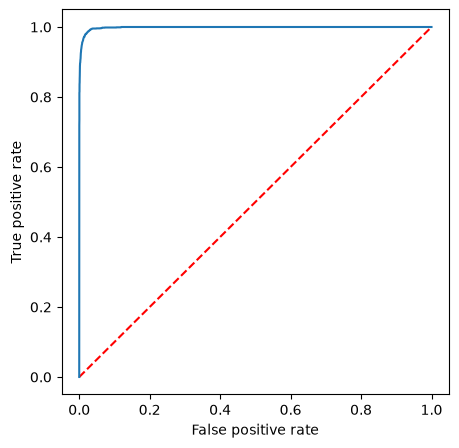

In [65]:
plt.figure(figsize=(5, 5))
plt.plot([0, 1], [0, 1], "r--")
plt.plot(
    lr_model.summary.roc.select("FPR").collect(),
    lr_model.summary.roc.select("TPR").collect(),
)

plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.show()

In [66]:
grid_search = (
    ParamGridBuilder()
    .addGrid(lr.elasticNetParam, [0.0, 1.0])
    .build()
)

In [67]:
grid_search

[{Param(parent='LogisticRegression_3def76ce70d4', name='elasticNetParam', doc='the ElasticNet mixing parameter, in range [0, 1]. For alpha = 0, the penalty is an L2 penalty. For alpha = 1, it is an L1 penalty.'): 0.0},
 {Param(parent='LogisticRegression_3def76ce70d4', name='elasticNetParam', doc='the ElasticNet mixing parameter, in range [0, 1]. For alpha = 0, the penalty is an L2 penalty. For alpha = 1, it is an L1 penalty.'): 1.0}]

![](../images/Three-fold_cross-validation.png)

In [68]:
from pyspark.ml.tuning import CrossValidator

In [69]:
cv = CrossValidator(
    estimator=food_pipeline,
    estimatorParamMaps=grid_search,
    evaluator=evaluator,
    numFolds=3,
    seed=13,
    collectSubModels=True,
)

cv_model = cv.fit(train)

cv_model.avgMetrics

[np.float64(0.9883947708313036), np.float64(0.9883931294765796)]

In [70]:
pipeline_food_model = cv_model.bestModel

## **Getting the biggest drivers from our model: Extracting the coefficients**

In [71]:
feature_names = ["(Intercept)"] + [
    x["name"]
    for x in (
        food_feature
            .schema["features"]
            .metadata["ml_attr"]["attrs"]["numeric"]
    )
]

feature_names

['(Intercept)',
 'food_processor',
 'buttermilk',
 'quince',
 'meat',
 'stir_fry',
 'olive',
 'backyard_bbq',
 'france',
 'persimmon',
 'hanukkah',
 'self',
 'appetizer',
 'sugar_snap_pea',
 'blue_cheese',
 'oyster',
 'veal',
 'cumin',
 'graduation',
 'whiskey',
 'pastry',
 'engagement_party',
 'salad_dressing',
 'beef_tenderloin',
 'nutmeg',
 'monterey_jack',
 'margarita',
 'portland',
 'snack',
 'parade',
 'jícama',
 'sesame',
 'marsala',
 'quick_and_healthy',
 'sauté',
 'pernod',
 'candy_thermometer',
 'vegetable',
 'berry',
 'tortillas',
 'trout',
 'wok',
 'green_bean',
 'lamb_chop',
 'prosciutto',
 'lobster',
 'banana',
 'lentil',
 'scotch',
 'blueberry',
 'cocktail_party',
 'nut',
 'slow_cooker',
 'kirsch',
 'strawberry',
 'party',
 'bread',
 'watercress',
 'low_cholesterol',
 'snapper',
 'lamb_shank',
 'clove',
 'chestnut',
 'back_to_school',
 'harpercollins',
 'jam_or_jelly',
 'brine',
 'missouri',
 'mussel',
 'carrot',
 'chocolate',
 'pepper',
 'los_angeles',
 'leek',
 'phyllo

In [72]:
feature_coefficients = [lr_model.intercept] + list(lr_model.coefficients.values)

feature_coefficients

[-2.435462551574762,
 np.float64(-0.4681902943087827),
 np.float64(-4.855847524852722),
 np.float64(-0.5872954555733771),
 np.float64(-13.049846567261863),
 np.float64(-1.2869204668070022),
 np.float64(-6.0835968825821025),
 np.float64(-2.4361622951648454),
 np.float64(-0.4536451803677823),
 np.float64(1.379168561755504),
 np.float64(-2.226766934942293),
 np.float64(1.9834221617123071),
 np.float64(-15.475850283668112),
 np.float64(-7.693887721725815),
 np.float64(-2.5610877532984184),
 np.float64(-1.8672188953756772),
 np.float64(-5.119849179038747),
 np.float64(-6.622624475101198),
 np.float64(-5.844341966660327),
 np.float64(1.799982341974054),
 np.float64(-1.5598105884333004),
 np.float64(1.533477105327265),
 np.float64(-7.5323681718728395),
 np.float64(-10.38819375989938),
 np.float64(-0.3227244870442045),
 np.float64(-3.7150470393250354),
 np.float64(-3.4739192118161157),
 np.float64(1.6132352859394192),
 np.float64(3.744210582588817),
 np.float64(6.3144252004814305),
 np.float64

In [73]:
coefficients = pd.DataFrame(
    feature_coefficients, 
    index=feature_names, 
    columns=["coef"]
)

coefficients["abs_coef"] = coefficients["coef"].abs()

coefficients.sort_values(["abs_coef"])

,coef,abs_coef
macadamia_nut,0.001570,0.001570
nut,0.003841,0.003841
mardi_gras,-0.011203,0.011203
ricotta,-0.031293,0.031293
ground_lamb,0.033383,0.033383
...,...,...
shavuot,18.048542,18.048542
sage,-18.527345,18.527345
low_sugar,-19.195353,19.195353
arugula,-20.862286,20.862286


In [74]:
pipeline_food_model.write().overwrite().save("../models/predictive_model_dessert")

In [75]:
loaded_model = PipelineModel.load("../models/predictive_model_dessert")

# **Building custom ML transformers and estimators**

## **Creating your own transformer**

![](../images/Custome_Transformer.png)

In [78]:
import pyspark.sql.functions as F
from pyspark.sql import Column, DataFrame

In [84]:
test_df = spark.createDataFrame(
    [[1, 2, 4, 1], [3, 6, 5, 4], [9, 4, None, 9], [11, 17, None, 3]],
    ["one", "two", "three", "four"],
)

test_df.show()

+---+---+-----+----+
|one|two|three|four|
+---+---+-----+----+
|  1|  2|    4|   1|
|  3|  6|    5|   4|
|  9|  4| NULL|   9|
| 11| 17| NULL|   3|
+---+---+-----+----+



In [85]:
def scalarNAFillerFunction(
    df: DataFrame, inputCol: Column, outputCol: str, filler: float = 0.0
):
    return df.withColumn(outputCol, inputCol).fillna(
        filler, subset=outputCol
    )

In [90]:
scalarNAFillerFunction(test_df, F.col('three'), 'three', -99.0).show()

+---+---+-----+----+
|one|two|three|four|
+---+---+-----+----+
|  1|  2|    4|   1|
|  3|  6|    5|   4|
|  9|  4|  -99|   9|
| 11| 17|  -99|   3|
+---+---+-----+----+



In [99]:
from pyspark.ml.param import Param, Params, TypeConverters

In [96]:
filler = Param(
    Params._dummy(),
    'filler',
    "Value we want to replace our null values with.",
    typeConverter=TypeConverters.toFloat, 
)

filler

Param(parent='undefined', name='filler', doc='Value we want to replace our null values with.')

In [98]:
class HasInputCols(Params):
    """Mixin for param inputCols: input column names."""

    inputCols = Param(
        Params._dummy(),
        "inputCols", "input column names.",
        typeConverter=TypeConverters.toListString,
    )

    def __init__(self):
        super(HasInputCols, self).__init__()

    def getInputCols(self):
        """Gets the value of inputCols or its default value. """
        return self.getOrDefault(self.inputCols)

In [101]:
from pyspark.ml import Transformer
from pyspark.ml.param.shared import HasInputCol, HasOutputCol

In [102]:
from pyspark import keyword_only

In [110]:
class ScalarNAFiller(Transformer, HasInputCol, HasOutputCol):

    filler = Param(
        Params._dummy(),
        'filler',
        "Value we want to replace our null values with.",
        typeConverter=TypeConverters.toFloat,
    )
    
    @keyword_only
    def __init__(self, inputCol=None, outputCol=None, filler=None):
        super().__init__()
        self._setDefault(filler=None)
        kwargs = self._input_kwargs
        self.setParams(**kwargs)
    
    @keyword_only
    def setParams(self, *, inputCol=None, outputCol=None, filler=None):
        kwargs = self._input_kwargs
        return self._set(**kwargs)

    def setFiller(self, new_filler):
        return self.setParams(filler=new_filler)

    def getFiller(self):
        return self.getOrDefault(self.filler)
    
    def setInputCol(self, new_inputCol):
        return self.setParams(inputCol=new_inputCol)

    def setOutputCol(self, new_outputCol):
        return self.setParams(outputCol=new_outputCol)

    def _transform(self, dataset):

        if not self.isSet("inputCol"):
            raise ValueError("No input column set for the ScalarNAFiller transformer.")

        input_column = dataset[self.getInputCol()]
        output_column = self.getOutputCol()
        na_filler = self.getFiller()
        return dataset.withColumn(output_column, input_column.cast("double")
                                 ).fillna(na_filler, output_column)

In [111]:
test_ScalarNAFiller = ScalarNAFiller(
    inputCol="three", outputCol="three", filler=-99
)

test_ScalarNAFiller.transform(test_df).show()

+---+---+-----+----+
|one|two|three|four|
+---+---+-----+----+
|  1|  2|  4.0|   1|
|  3|  6|  5.0|   4|
|  9|  4|-99.0|   9|
| 11| 17|-99.0|   3|
+---+---+-----+----+



![](../images/Setting_Param.png)

In [112]:
# We modify test_ScalarNAFiller in place.
test_ScalarNAFiller.setFiller(17).transform(test_df).show()

+---+---+-----+----+
|one|two|three|four|
+---+---+-----+----+
|  1|  2|  4.0|   1|
|  3|  6|  5.0|   4|
|  9|  4| 17.0|   9|
| 11| 17| 17.0|   3|
+---+---+-----+----+



In [113]:
# We temporarily override the filler Param without changing test_ScalarNAFiller in place.
test_ScalarNAFiller.transform(
    test_df, params={test_ScalarNAFiller.filler: 17}
).show()

+---+---+-----+----+
|one|two|three|four|
+---+---+-----+----+
|  1|  2|  4.0|   1|
|  3|  6|  5.0|   4|
|  9|  4| 17.0|   9|
| 11| 17| 17.0|   3|
+---+---+-----+----+



## **Creating your own estimator**

![](../images/ExtremeValueCapperModel.png)

![](../images/Design_ExtremeValueCapper.png)

In [114]:
def test_ExtremeValueCapperModel_transform(
    df: DataFrame,
    inputCol: Column,
    outputCol: str,
    cap: float,
    floor: float,
):

    return df.withColumn(
        outputCol,
        F.when(inputCol > cap, cap)
            .when(inputCol < floor, floor)
            .otherwise(inputCol),
    )

def test_ExtremeValueCapper_fit(
    df: DataFrame, 
    inputCol: Column, 
    outputCol: str, 
    boundary: float
):
    
    avg, stddev = df.agg(
        F.mean(inputCol), F.stddev(inputCol)
    ).head()

    cap = avg + boundary * stddev
    floor = avg - boundary * stddev

    return test_ExtremeValueCapperModel_transform(
        df, inputCol, outputCol, cap, floor
    )

![](../images/Design_ExtremeValueCapperParams_Mixin.png)

In [117]:
class _ExtremeValueCapperParams(HasInputCol, HasOutputCol):
    
    boundary = Param(
        Params._dummy(),
        "boundary",
        "Multiple of standard deviation for the cap and floor. Default = 0.0.",
        TypeConverters.toFloat,
    )

    def __init__(self, *args):
        super().__init__(*args)
        self._setDefault(boundary=0.0)

    def getBoundary(self):
        return self.getOrDefault(self.boundary)

In [115]:
from pyspark.ml import Model

In [125]:
class ExtremeValueCapperModel(Model, _ExtremeValueCapperParams):

    cap = Param(
        Params._dummy(),
        "cap",
        "Upper bound of the values `inputCol` can take."
        "Values will be capped to this value.",
        TypeConverters.toFloat,
    )

    floor = Param(
        Params._dummy(),
        "floor",
        "Lower bound of the values `inputCol` can take."
        "Values will be floored to this value.",
        TypeConverters.toFloat,
    )

    @keyword_only
    def __init__(self, inputCol=None, outputCol=None, cap=None, floor=None):
        super().__init__()
        kwargs = self._input_kwargs
        self.setParams(**kwargs)

    @keyword_only
    def setParams(self, inputCol=None, outputCol=None, cap=None, floor=None):
        kwargs = self._input_kwargs
        return self._set(**kwargs)

    def _transform(self, dataset):
        if not self.isSet("inputCol"):
            raise ValueError(
                "No input column set for the "
                "ExtremeValueCapperModel transformer."
            )

        input_column = dataset[self.getInputCol()]
        output_column = self.getOutputCol()
        cap_value = self.getOrDefault("cap")
        floor_value = self.getOrDefault("floor")

        return dataset.withColumn(
            output_column,
            F.when(input_column > cap_value, cap_value)
                .when(input_column < floor_value, floor_value)
                .otherwise(input_column),
        )

![](../images/ExtremeValueCaper_Estimator.png)

In [119]:
from pyspark.ml import Estimator

In [126]:
class ExtremeValueCapper(Estimator, _ExtremeValueCapperParams):

    @keyword_only
    def __init__(self, inputCol=None, outputCol=None, boundary=None):
        super().__init__()
        kwargs = self._input_kwargs
        self.setParams(**kwargs)

    @keyword_only
    def setParams(self, inputCol=None, outputCol=None, boundary=None):
        kwargs = self._input_kwargs
        return self._set(**kwargs)

    def _fit(self, dataset):
        input_column = self.getInputCol()
        output_column = self.getOutputCol()
        boundary = self.getBoundary()

        avg, stddev = dataset.agg(
            F.mean(input_column), F.stddev(input_column)
        ).head()

        cap_value = avg + boundary * stddev
        floor_value = avg - boundary * stddev

        return ExtremeValueCapperModel(
            inputCol=input_column,
            outputCol=output_column,
            cap=cap_value,
            floor=floor_value,
        )

In [127]:
test_EVC = ExtremeValueCapper(
    inputCol="one", outputCol="five", boundary=1.0
)

test_EVC.fit(test_df).transform(test_df).show()

+---+---+-----+----+------------------+
|one|two|three|four|              five|
+---+---+-----+----+------------------+
|  1|  2|    4|   1|1.2390477143047667|
|  3|  6|    5|   4|               3.0|
|  9|  4| NULL|   9|               9.0|
| 11| 17| NULL|   3|10.760952285695232|
+---+---+-----+----+------------------+



## **Using Custome transformer and estimator in an ML pipeline**

### **Dealing with multiple inputCols**

In [131]:
from pyspark.ml.param.shared import HasInputCols, HasOutputCols
from pyspark.ml.util import DefaultParamsReadable, DefaultParamsWritable

In [139]:
class ScalarNAFiller(
    Transformer,
    HasInputCol,
    HasOutputCol,
    HasInputCols,
    HasOutputCols,
    DefaultParamsReadable,
    DefaultParamsWritable,
):
    """Fills the `null` values of inputCol with a scalar value `filler`."""

    filler = Param(
        Params._dummy(),
        "filler",
        "Value we want to replace our null values with.",
        typeConverter=TypeConverters.toFloat,
    )

    @keyword_only
    def __init__(
        self,
        inputCol=None,
        outputCol=None,
        inputCols=None,
        outputCols=None,
        filler=None,
    ):
        super().__init__()
        self._setDefault(filler=None)
        kwargs = self._input_kwargs
        self.setParams(**kwargs)

    @keyword_only
    def setParams(
        self,
        inputCol=None,
        outputCol=None,
        inputCols=None,
        outputCols=None,
        filler=None,
    ):
        kwargs = self._input_kwargs
        return self._set(**kwargs)

    def setFiller(self, new_filler):
        return self.setParams(filler=new_filler)

    def setInputCol(self, new_inputCol):
        return self.setParams(inputCol=new_inputCol)

    def setOutputCol(self, new_outputCol):
        return self.setParams(outputCol=new_outputCol)

    def setInputCols(self, new_inputCols):
        return self.setParams(inputCols=new_inputCols)

    def setOutputCols(self, new_outputCols):
        return self.setParams(outputCols=new_outputCols)

    def getFiller(self):
        return self.getOrDefault(self.filler)

    def checkParams(self):
        # Test #1: either inputCol or inputCols can be set (but not both).
        if self.isSet("inputCol") and (self.isSet("inputCols")):
            raise ValueError(
                "Only one of `inputCol` and `inputCols`" "must be set."
            )

        # Test #2: at least one of inputCol or inputCols must be set.
        if not (self.isSet("inputCol") or self.isSet("inputCols")):
            raise ValueError(
                "One of `inputCol` or `inputCols` must be set."
            )

        # Test #3: if `inputCols` is set, then `outputCols`
        # must be a list of the same len()
        if self.isSet("inputCols"):
            if len(self.getInputCols()) != len(self.getOutputCols()):
                raise ValueError(
                    "The length of `inputCols` does not match"
                    " the length of `outputCols`"
                )

    def _transform(self, dataset):
        self.checkParams()

        # If `inputCol` / `outputCol`, we wrap into a single-item list
        input_columns = (
            [self.getInputCol()]
            if self.isSet("inputCol")
            else self.getInputCols()
        )
        output_columns = (
            [self.getOutputCol()]
            if self.isSet("outputCol")
            else self.getOutputCols()
        )

        answer = dataset

        # If input_columns == output_columns, we overwrite and no need to create
        # new columns.
        if input_columns != output_columns:
            for in_col, out_col in zip(input_columns, output_columns):
                answer = answer.withColumn(out_col, F.col(in_col))

        na_filler = self.getFiller()
        return answer.fillna(na_filler, output_columns)


In [140]:
class _ExtremeValueCapperParams(
    HasInputCol, HasOutputCol, DefaultParamsWritable, DefaultParamsReadable
):

    boundary = Param(
        Params._dummy(),
        "boundary",
        "Multiple of standard deviation for the cap and floor. Default = 0.0.",
        TypeConverters.toFloat,
    )

    def __init__(self, *args):
        super().__init__(*args)
        self._setDefault(boundary=0.0)

    def getBoundary(self):
        return self.getOrDefault(self.boundary)


class ExtremeValueCapperModel(Model, _ExtremeValueCapperParams):

    cap = Param(
        Params._dummy(),
        "cap",
        "Upper bound of the values `inputCol` can take."
        "Values will be capped to this value.",
        TypeConverters.toFloat,
    )
    floor = Param(
        Params._dummy(),
        "floor",
        "Lower bound of the values `inputCol` can take."
        "Values will be floored to this value.",
        TypeConverters.toFloat,
    )

    @keyword_only
    def __init__(
        self, inputCol=None, outputCol=None, cap=None, floor=None
    ):
        super().__init__()
        kwargs = self._input_kwargs
        self.setParams(**kwargs)

    @keyword_only
    def setParams(
        self, inputCol=None, outputCol=None, cap=None, floor=None
    ):
        kwargs = self._input_kwargs
        return self._set(**kwargs)

    def setCap(self, new_cap):
        return self.setParams(cap=new_cap)

    def setFloor(self, new_floor):
        return self.setParams(floor=new_floor)

    def setInputCol(self, new_inputCol):
        return self.setParams(inputCol=new_inputCol)

    def setOutputCol(self, new_outputCol):
        return self.setParams(outputCol=new_outputCol)

    def getCap(self):
        return self.getOrDefault(self.cap)

    def getFloor(self):
        return self.getOrDefault(self.floor)

    def _transform(self, dataset):
        if not self.isSet("inputCol"):
            raise ValueError(
                "No input column set for the "
                "ExtremeValueCapperModel transformer."
            )
        input_column = dataset[self.getInputCol()]
        output_column = self.getOutputCol()
        cap_value = self.getOrDefault("cap")
        floor_value = self.getOrDefault("floor")

        return dataset.withColumn(
            output_column,
            F.when(input_column > cap_value, cap_value)
            .when(input_column < floor_value, floor_value)
            .otherwise(input_column),
        )

In [141]:
class ExtremeValueCapper(Estimator, _ExtremeValueCapperParams):
    @keyword_only
    def __init__(self, inputCol=None, outputCol=None, boundary=None):
        super().__init__()
        kwargs = self._input_kwargs
        self.setParams(**kwargs)

    @keyword_only
    def setParams(self, inputCol=None, outputCol=None, boundary=None):
        kwargs = self._input_kwargs
        return self._set(**kwargs)

    def setBoundary(self, new_boundary):
        self.setParams(boundary=new_boundary)

    def setInputCol(self, new_inputCol):
        return self.setParams(inputCol=new_inputCol)

    def setOutputCol(self, new_outputCol):
        return self.setParams(outputCol=new_outputCol)

    def _fit(self, dataset):
        input_column = self.getInputCol()
        output_column = self.getOutputCol()
        boundary = self.getBoundary()

        avg, stddev = dataset.agg(
            F.mean(input_column), F.stddev(input_column)
        ).head()

        cap_value = avg + boundary * stddev
        floor_value = avg - boundary * stddev
        return ExtremeValueCapperModel(
            inputCol=input_column,
            outputCol=output_column,
            cap=cap_value,
            floor=floor_value,
        )

In [142]:
scalar_na_filler = ScalarNAFiller(
    inputCols=BINARY_COLUMNS, outputCols=BINARY_COLUMNS, filler=0.0
)

extreme_value_capper_cal = ExtremeValueCapper(
    inputCol="calories", outputCol="calories", boundary=2.0
)

extreme_value_capper_pro = ExtremeValueCapper(
    inputCol="protein", outputCol="protein", boundary=2.0
)

extreme_value_capper_fat = ExtremeValueCapper(
    inputCol="fat", outputCol="fat", boundary=2.0
)

extreme_value_capper_sod = ExtremeValueCapper(
    inputCol="sodium", outputCol="sodium", boundary=2.0
)

In [143]:
food_pipeline = Pipeline(
    stages=[
        scalar_na_filler,
        extreme_value_capper_cal,
        extreme_value_capper_pro,
        extreme_value_capper_fat,
        extreme_value_capper_sod,
        imputer,
        continuous_assembler,
        continuous_scaler,
        preml_assembler,
        lr,
    ]
)    

In [144]:
train, test = food.randomSplit([0.7, 0.3], 13)

food_pipeline_model = food_pipeline.fit(train)

results = food_pipeline_model.transform(test)

evaluator = BinaryClassificationEvaluator(
    labelCol="dessert",
    rawPredictionCol="rawPrediction",
    metricName="areaUnderROC",
)

accuracy = evaluator.evaluate(results)
print(f"Area under ROC = {accuracy} ")

[Stage 2421:>                                                       (0 + 4) / 4]

Area under ROC = 0.9926518410478761 


In [145]:
food_pipeline_model.save("../models/food_pipeline.model")